<a href="https://colab.research.google.com/github/navyad-a/navya-a/blob/main/BAI702_Diabetes_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Diabetes Prediction Using Machine Learning Algorithms


Subject: Machine Learning–II (BAI702)

Programme: B.E CSE (AI & ML), 7th Semester

Student: Navya D A USN: 1AM23CI094

College: AMC ENGINEERING COLLEGE


1. Problem Statement

Build and compare supervised machine-learning classification models that predict the Outcome label in the Pima Indians Diabetes dataset using eight input features.

2. Objectives

- Load and understand a publicly available Kaggle dataset.
- Inspect data quality and perform exploratory data analysis (EDA).
- Handle implausible zero values in selected medical measurements.
- Train and compare Logistic Regression, K-Nearest Neighbors, Decision Tree, and Random Forest.
- Evaluate models using accuracy, precision, recall, F1-score, and confusion matrices.
Important limitation: This is an educational exercise on a specific historical dataset, not a medical diagnostic tool. It must not be used to diagnose a person or guide treatment.

3. Dataset

Download diabetes.csv from the Kaggle Pima Indians Diabetes Database. In Colab, use the upload cell below. The commonly distributed file contains eight predictors and the target column Outcome (0 = negative class, 1 = positive class).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()  # Select diabetes.csv from your computer


Saving archive.zip to archive.zip


In [ ]:
# Read the uploaded CSV file
filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn information:")
df.info()
print("\\nMissing values per column:")
display(df.isna().sum())
print("\\nTarget distribution:")
display(df.value_counts())


Dataset shape: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


\nColumn information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
\nMissing values per column:


,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


\nTarget distribution:


gender  age   hypertension  heart_disease  smoking_history  bmi    HbA1c_level  blood_glucose_level  diabetes
Female  80.0  0             0              No Info          27.32  6.2          90                   0           9
                                                                   6.5          159                  0           9
                                                                   4.0          85                   0           8
                                                                                158                  0           7
                                                                   4.5          140                  0           7
                                                                                                                ..
        48.0  0             0              never            27.32  6.5          90                   0           1
                                                                                85                   0           1
                                                                   6.2          159                  0           1
                                                                                145                  0           1
                                                            27.58  4.0          160                  0           1
Name: count, Length: 96146, dtype: int64

5. Exploratory Data Analysis (EDA)


,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.885856,22.516840,0.08,24.00,43.00,60.00,80.00
hypertension,100000.0,0.074850,0.263150,0.00,0.00,0.00,0.00,1.00
heart_disease,100000.0,0.039420,0.194593,0.00,0.00,0.00,0.00,1.00
bmi,100000.0,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.527507,1.070672,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058060,40.708136,80.00,100.00,140.00,159.00,300.00
diabetes,100000.0,0.085000,0.278883,0.00,0.00,0.00,0.00,1.00


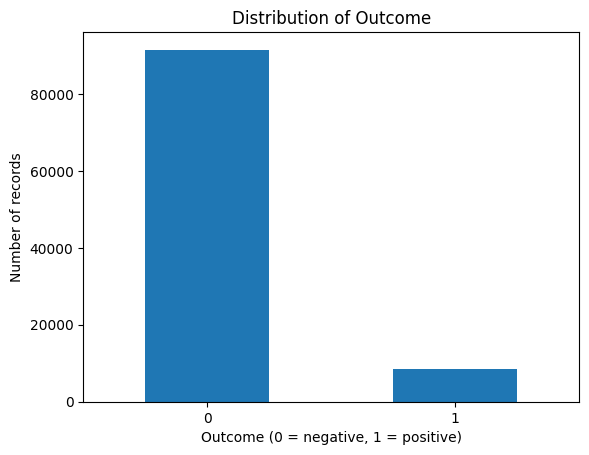

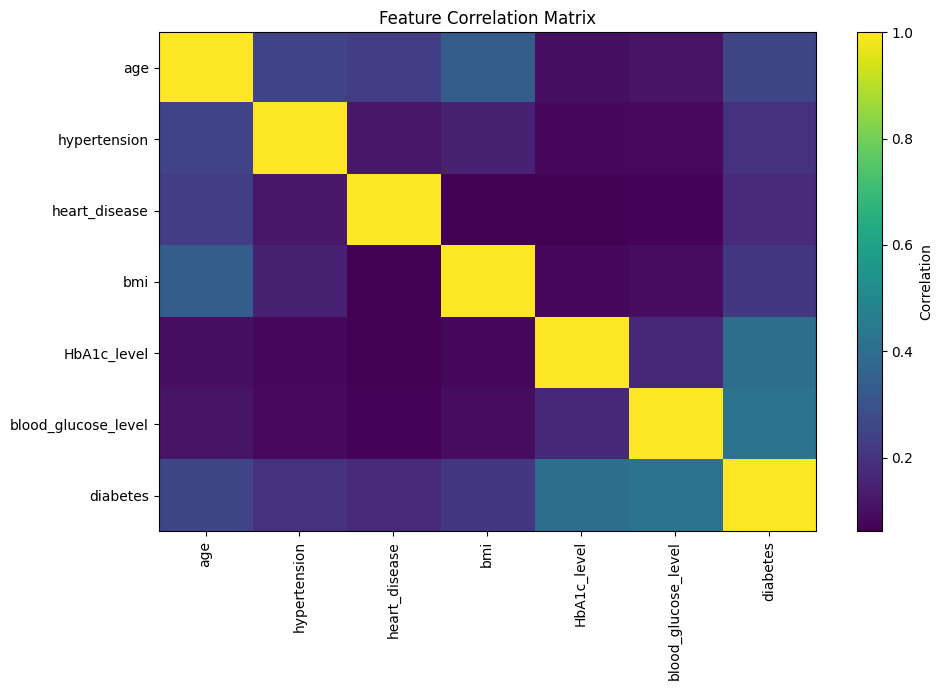

In [ ]:
# Summary statistics
display(df.describe().T)

# Target-class distribution
if 'diabetes' in df.columns:
    df['diabetes'].value_counts().sort_index().plot(kind="bar")
else:
    # Fallback to general value_counts if target name is different
    df.iloc[:, -1].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Outcome")
plt.xlabel("Outcome (0 = negative, 1 = positive)")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.show()

# Correlation heatmap using Matplotlib only
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(corr, aspect="auto")
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

6. Data cleaning and train-test split

In this dataset, zero values in Glucose, BloodPressure, SkinThickness, Insulin, and BMI are often treated as missing/implausible measurements. We convert those zeros to missing values, then impute using the median calculated from training data only. Pregnancies can legitimately be zero, so it is not changed.

A pipeline keeps imputation and scaling inside each model workflow, reducing data leakage. Scaling is important for Logistic Regression and KNN; tree-based models generally do not require it, but using a common pipeline keeps the comparison consistent.

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

data = df.copy()

# Map columns from the Kaggle Diabetes Prediction Dataset to the expected format
column_mapping = {
    'diabetes': 'Outcome',
    'blood_glucose_level': 'Glucose',
    'hypertension': 'BloodPressure',
    'heart_disease': 'SkinThickness'
}

if 'diabetes' in data.columns and 'Outcome' not in data.columns:
    data = data.rename(columns=column_mapping)
    # Create other expected columns filled with NaN to avoid KeyError downstream
    for col in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]:
        if col not in data.columns:
            if col.lower() in data.columns:
                data[col] = data[col.lower()]
            else:
                data[col] = np.nan

# Convert zeros to missing values where appropriate
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in zero_as_missing:
    if col in data.columns:
        data[col] = data[col].replace(0, np.nan)

X = data.drop(columns="Outcome")
y = data["Outcome"].astype(int)

# Extract numeric columns so the imputer/scaler does not complain about text values
numeric_cols = X.select_dtypes(include=[np.number]).columns
X_numeric = X[numeric_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X_numeric, y, test_size=0.20, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Missing values in selected columns after zero handling:")
display(X_train.isna().sum())

Training records: 80000
Testing records: 20000
Missing values in selected columns after zero handling:


,0
age,0
BloodPressure,74013
SkinThickness,76840
bmi,0
HbA1c_level,0
Glucose,0
Insulin,80000
BMI,0


7. Train and evaluate four classification models

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(max_depth=5, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced"))
    ])
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })
    print(f"\n===== {name} =====")
    print(classification_report(y_test, predictions, target_names=["Outcome 0", "Outcome 1"], zero_division=0))

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
display(results_df.round(3))


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Insulin']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Insulin']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



===== Logistic Regression =====
              precision    recall  f1-score   support

   Outcome 0       0.97      0.99      0.98     18300
   Outcome 1       0.87      0.62      0.73      1700

    accuracy                           0.96     20000
   macro avg       0.92      0.81      0.85     20000
weighted avg       0.96      0.96      0.96     20000



/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Insulin']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Insulin']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



===== KNN =====
              precision    recall  f1-score   support

   Outcome 0       0.97      0.99      0.98     18300
   Outcome 1       0.91      0.66      0.77      1700

    accuracy                           0.97     20000
   macro avg       0.94      0.83      0.88     20000
weighted avg       0.96      0.97      0.96     20000



/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Insulin']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Insulin']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



===== Decision Tree =====
              precision    recall  f1-score   support

   Outcome 0       0.97      1.00      0.99     18300
   Outcome 1       1.00      0.67      0.81      1700

    accuracy                           0.97     20000
   macro avg       0.99      0.84      0.90     20000
weighted avg       0.97      0.97      0.97     20000



/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Insulin']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Insulin']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



===== Random Forest =====
              precision    recall  f1-score   support

   Outcome 0       0.97      0.99      0.98     18300
   Outcome 1       0.85      0.70      0.77      1700

    accuracy                           0.96     20000
   macro avg       0.91      0.84      0.87     20000
weighted avg       0.96      0.96      0.96     20000



,Model,Accuracy,Precision,Recall,F1-score
2,Decision Tree,0.972,1.000,0.674,0.805
1,KNN,0.966,0.911,0.665,0.769
3,Random Forest,0.964,0.847,0.701,0.767
0,Logistic Regression,0.960,0.869,0.623,0.726


8. Visualize model comparison and confusion matrices

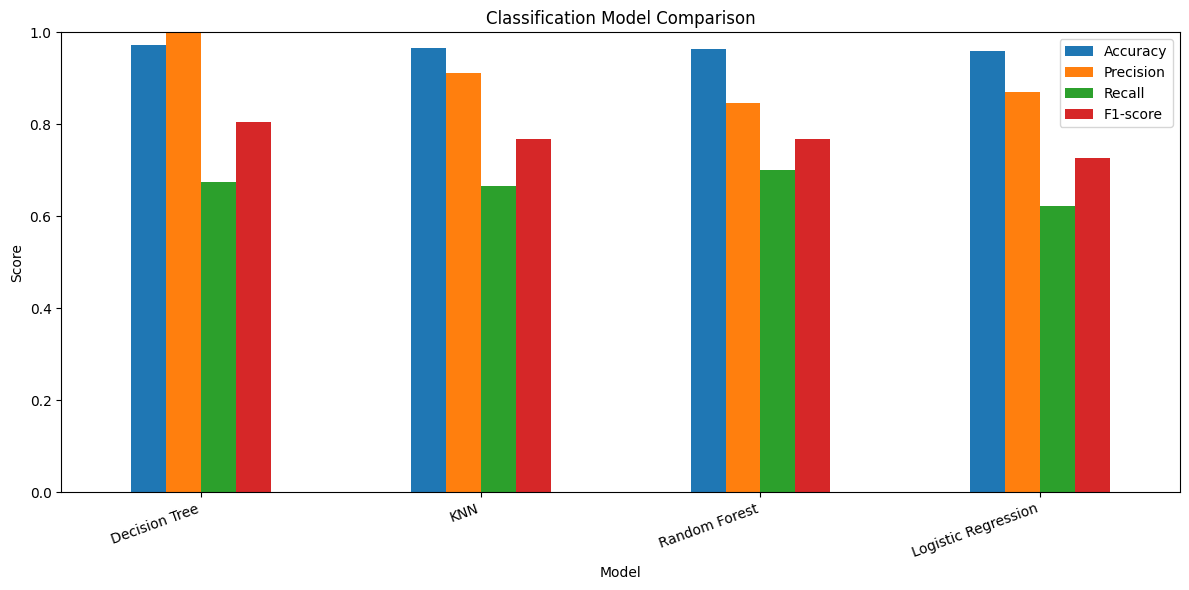

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Insulin']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


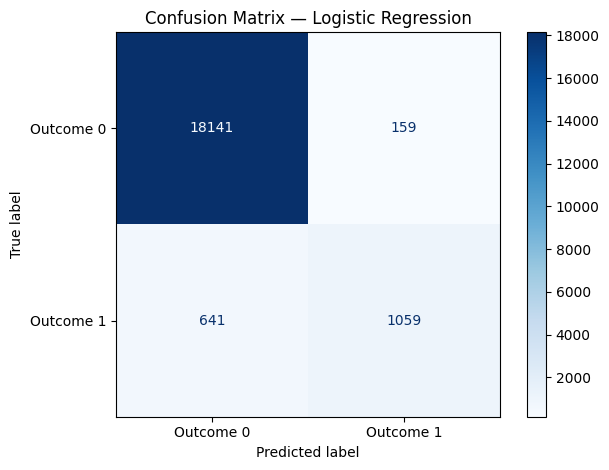

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Insulin']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


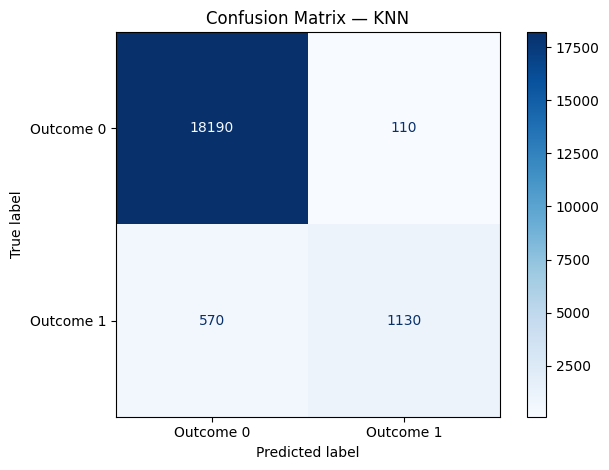

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Insulin']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


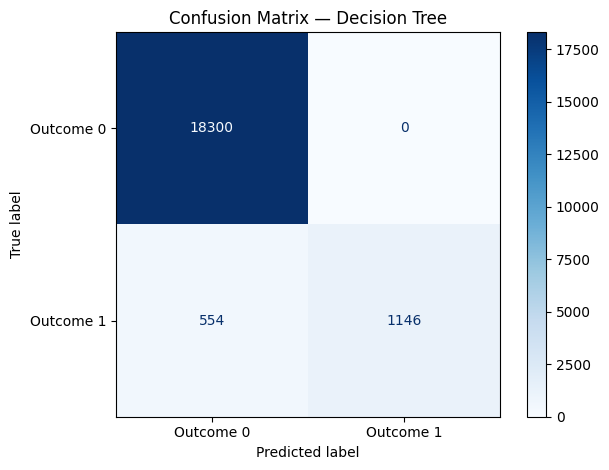

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Insulin']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


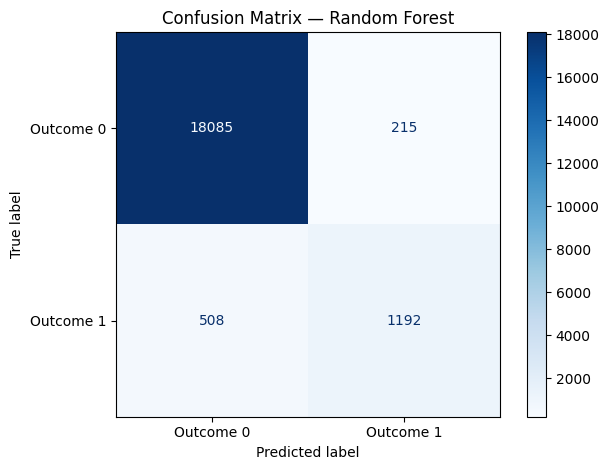

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1)
)
plt.title("Classification Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

for name, model in models.items():
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=["Outcome 0", "Outcome 1"], cmap="Blues"
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()


9. Results and Discussion

Use the results_df table produced by your own run. Do not copy or invent performance values. Identify the best model according to the metric you choose (for example, F1-score), and explain the trade-off between precision and recall. Since the dataset is small and class distribution is uneven, accuracy alone is not sufficient.

Best model by F1-score in this run:

In [ ]:
best_model_name = results_df.iloc[0]["Model"]
print("Best model by test F1-score:", best_model_name)
print(results_df.iloc[0].to_dict())


Best model by test F1-score: Decision Tree
{'Model': 'Decision Tree', 'Accuracy': 0.9723, 'Precision': 1.0, 'Recall': 0.6741176470588235, 'F1-score': 0.8053408292340126}


10. Conclusion

This mini-project demonstrates a complete supervised-learning workflow: data inspection, EDA, handling selected zero values, splitting data into training and testing sets, model training, and evaluation. The final conclusion should be written after reviewing the measured results. The models are educational examples and should not be considered clinically validated.

11. References
1. Kaggle, Pima Indians Diabetes Database:https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset
2. Scikit-learn documentation, classification_report: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html
3. Scikit-learn documentation, confusion_matrix: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html